# 01 · Exploración y comparación con el oráculo

Carga la tabla horaria preprocesada, mira los perfiles diarios y compara lo que hace nuestro agente con la solución óptima con información perfecta.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from datathon.data import load_hourly, split
from datathon.evaluate import evaluate, oracle

df = load_hourly()
train, val = split(df)
df.head()

,load_kw,pv_kw,precio_eur_per_kwh,co2_kg_per_kwh,temp_amb_c,temp_panel_c,viento_ms,irradiancia_wm2
Fecha,,,,,,,,
2025-09-01 00:00:00,697.0,0.0,0.09770,0.065316,26.072727,26.009091,0.0,0.0
2025-09-01 01:00:00,697.0,0.0,0.08183,0.065991,25.141667,24.725000,0.0,0.0
2025-09-01 02:00:00,697.0,0.0,0.08855,0.069553,25.066667,24.733333,0.0,0.0
2025-09-01 03:00:00,697.0,0.0,0.08559,0.071810,25.316667,25.141667,0.0,0.0
2025-09-01 04:00:00,697.0,0.0,0.08297,0.071963,23.300000,23.308333,0.0,0.0


## Perfiles medios por hora
El objetivo pondera CO₂ (70%) y coste (30%). Lo que importa es **cuándo** cargar y descargar.

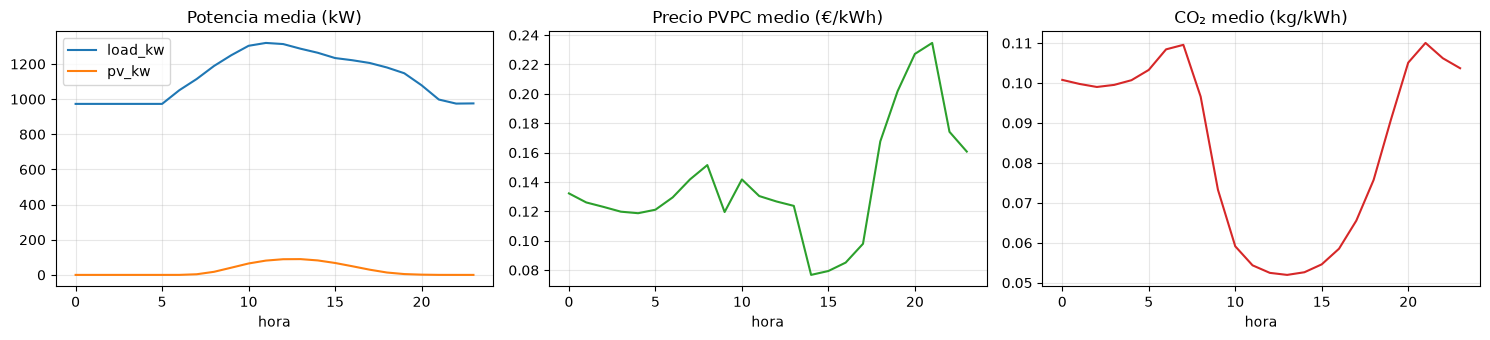

In [2]:
prof = df.groupby(df.index.hour)[["load_kw", "pv_kw", "precio_eur_per_kwh", "co2_kg_per_kwh"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
prof[["load_kw", "pv_kw"]].plot(ax=axes[0], title="Potencia media (kW)")
prof["precio_eur_per_kwh"].plot(ax=axes[1], title="Precio PVPC medio (€/kWh)", color="tab:green")
prof["co2_kg_per_kwh"].plot(ax=axes[2], title="CO₂ medio (kg/kWh)", color="tab:red")
for a in axes: a.set_xlabel("hora"); a.grid(alpha=.3)
plt.tight_layout()

## Peso marginal de cada hora
Como la carga neta del campus casi siempre supera los 500 kW, el score es prácticamente **lineal** en la potencia de la batería:

$w_t = 70\,\frac{CO2_t}{CO2_{base}} + 30\,\frac{precio_t}{Coste_{base}}$, y descargar 1 kWh en la hora $t$ aporta ≈ $w_t$ puntos.

Horas con carga neta < 500 kW: 31 de 5993


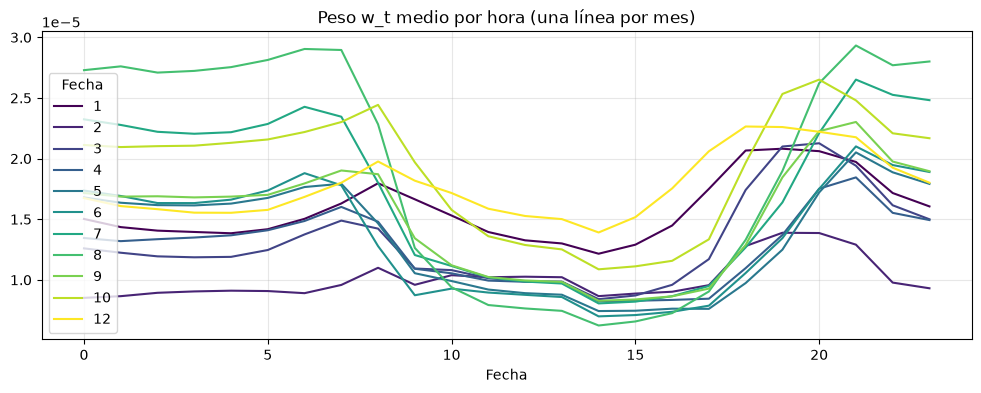

In [3]:
net = df.load_kw - df.pv_kw
print(f"Horas con carga neta < 500 kW: {(net < 500).sum()} de {len(df)}")
base = net.clip(lower=0)
w = 70 * df.co2_kg_per_kwh / (base @ df.co2_kg_per_kwh) + 30 * df.precio_eur_per_kwh / (base @ df.precio_eur_per_kwh)
w.groupby([w.index.month, w.index.hour]).mean().unstack(0).plot(figsize=(12, 4), title="Peso w_t medio por hora (una línea por mes)", cmap="viridis")
plt.grid(alpha=.3)

## Agente vs oráculo en validación

Agente:  1.38  (CO2 0.96%, coste 2.37%, infr 0)
Oráculo: 6.12  (CO2 5.80%, coste 6.88%)


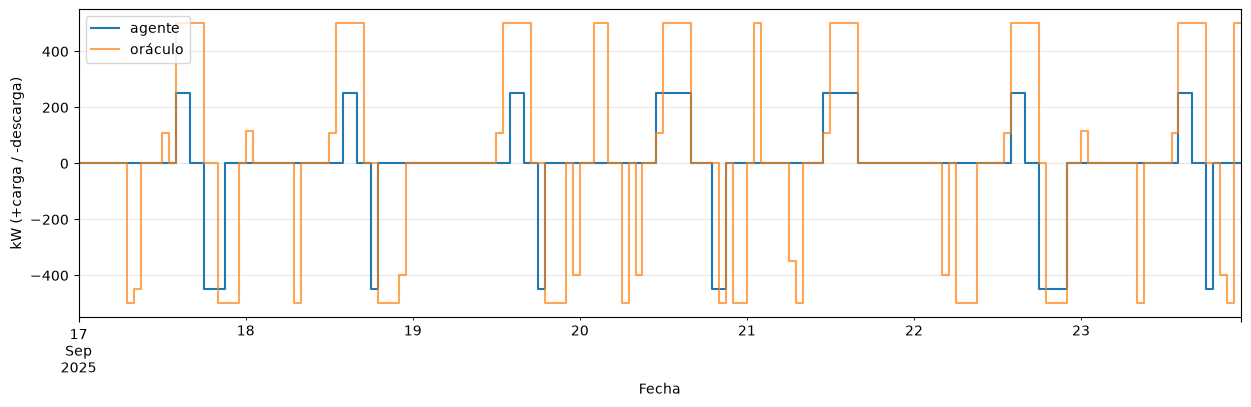

In [4]:
res = evaluate("../submission/agent.py", val)
orc = oracle(val)
print(f"Agente:  {res['score_oficial']:.2f}  (CO2 {res['co2_estalviat_pct']:.2f}%, coste {res['cost_estalviat_pct']:.2f}%, infr {res['infraccions']})")
print(f"Oráculo: {orc['score_oficial']:.2f}  (CO2 {orc['co2_estalviat_pct']:.2f}%, coste {orc['cost_estalviat_pct']:.2f}%)")

semana = val.index[:168]
fig, ax = plt.subplots(figsize=(15, 4))
res["acciones"].loc[semana].plot(ax=ax, label="agente", drawstyle="steps-post")
orc["acciones"].loc[semana].plot(ax=ax, label="oráculo", drawstyle="steps-post", alpha=.7)
ax.set_ylabel("kW (+carga / -descarga)"); ax.legend(); ax.grid(alpha=.3)